In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as msno
import xgboost as xgb
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import shap

In [ ]:
results_df = pd.read_excel("../../data/processed/results_data.xlsx")
results_df

,Model,MAE,RMSE,R²
0,Linear Regression,9.298022,11.508842,0.107653
1,Decision Tree,6.943456,9.309794,0.416084
2,Random Forest,6.922562,9.245581,0.424111
3,Bagging,6.920780,9.248181,0.423787
4,SVR,9.002595,11.419585,0.121441
5,XGBoost,7.008851,9.082760,0.444216
6,Voting,7.016261,9.170590,0.433415


In [ ]:
df = pd.read_excel("../../data/processed/mine_data_cleaned.xlsx")
df.columns = df.columns.str.strip()
df.head()

,YEAR,SEASON,MONTH,LOCATION,WEEK,Temperature,Relative_humidity,RF-CUMULATIVE,Wind_speed,PM10,PM2.5
0,2023,WINTER,DECEMBER,HAUL ROAD,1,30.1,64.5,1.0,2.55,56.8,42.6
1,2023,WINTER,DECEMBER,HAUL ROAD,1,29.2,70.3,1.0,2.55,62.4,41.9
2,2023,WINTER,DECEMBER,HAUL ROAD,2,27.6,68.0,0.0,2.55,63.9,43.6
3,2023,WINTER,DECEMBER,HAUL ROAD,2,24.5,85.3,0.0,2.55,65.7,41.9
4,2024,WINTER,DECEMBER,HAUL ROAD,3,28.8,58.9,0.0,2.55,60.2,39.5


In [12]:
features = [
    "Temperature",
    "Relative_humidity",
    "RF-CUMULATIVE",
    "Wind_speed"
]

target_pm10 = "PM10"
target_pm25 = "PM2.5"

In [15]:
X = df[features]
y = df[target_pm10]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

C:\Users\DELL\AppData\Local\Temp\ipykernel_17508\3588624545.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


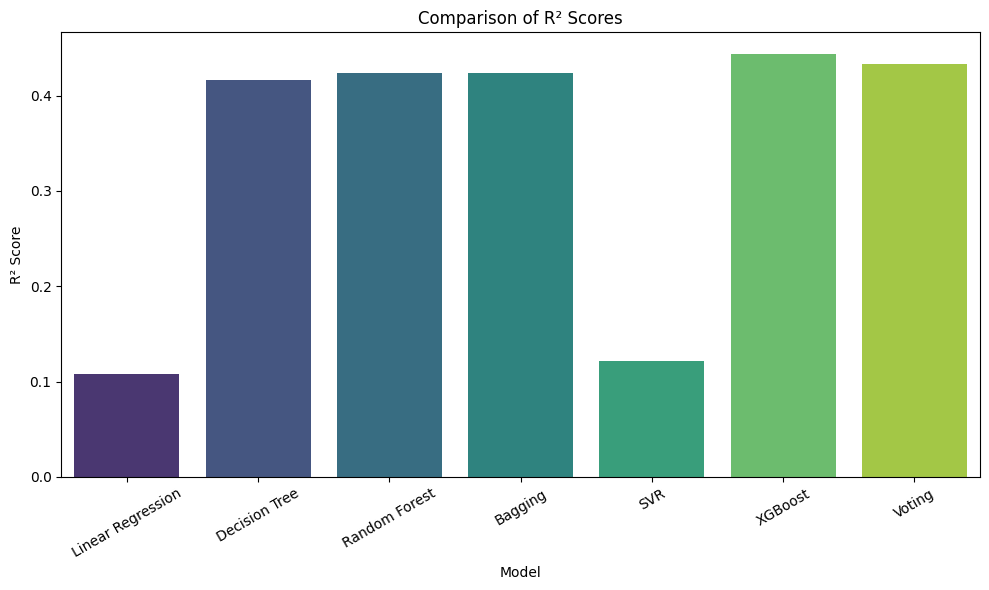

In [5]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R²",
    palette="viridis"
)

plt.title("Comparison of R² Scores")

plt.xticks(rotation=30)

plt.ylabel("R² Score")

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_17508\1072115408.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


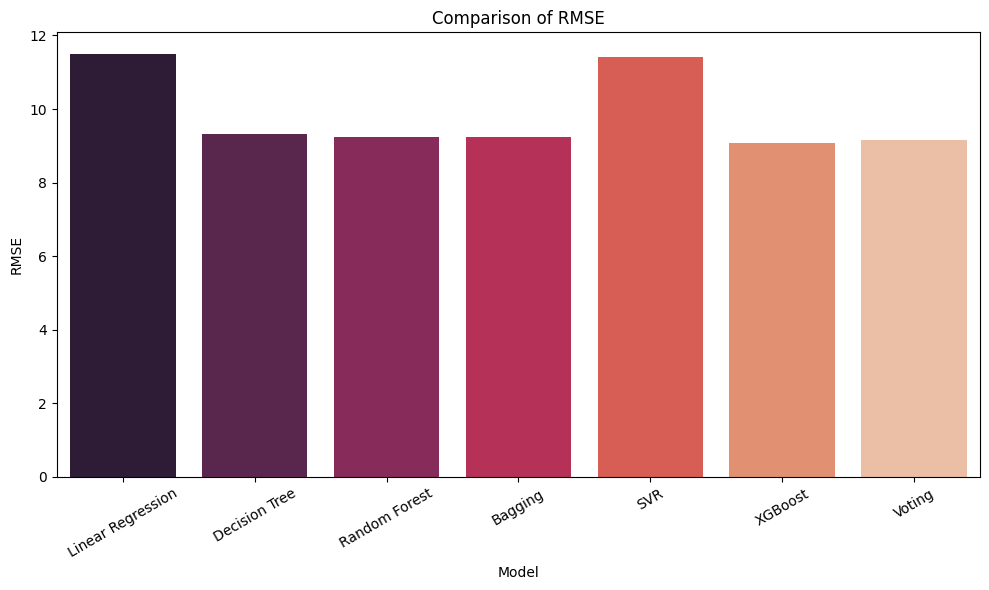

In [6]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    palette="rocket"
)

plt.title("Comparison of RMSE")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_17508\1874031892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


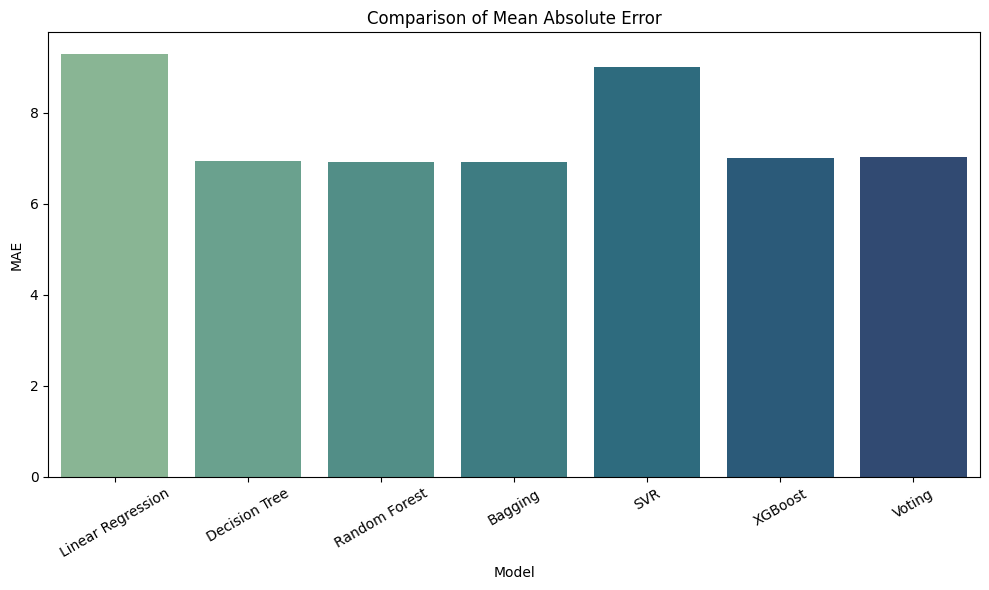

In [7]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    palette="crest"
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_17508\1874031892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


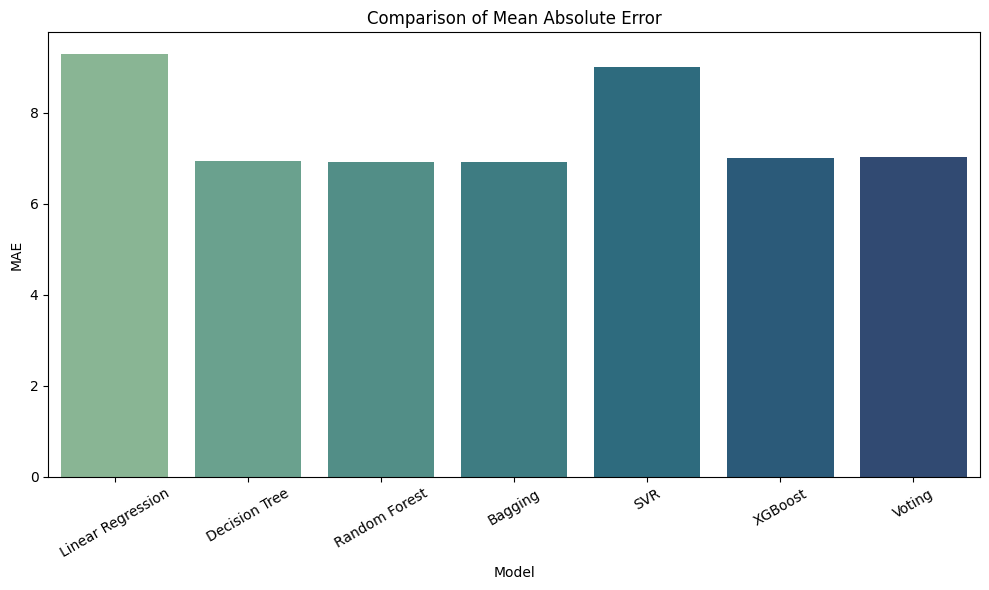

In [8]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    palette="crest"
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

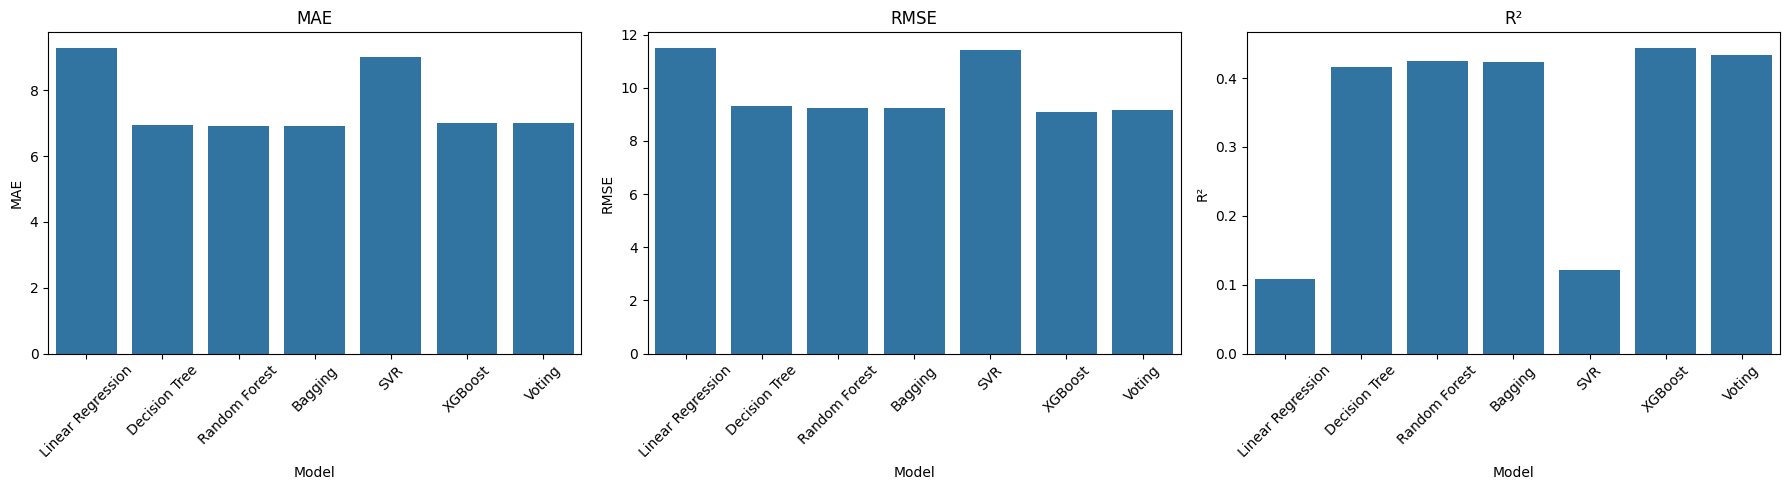

In [9]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[0]
)

axes[0].set_title("MAE")

axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)

axes[1].set_title("RMSE")

axes[1].tick_params(axis='x', rotation=45)

sns.barplot(
    data=results_df,
    x="Model",
    y="R²",
    ax=axes[2]
)

axes[2].set_title("R²")

axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.show()

In [20]:
# XGBoost
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

In [23]:
mae = mean_absolute_error(y_test, xgb_pred)
rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
r2 = r2_score(y_test, xgb_pred)

print(mae)
print(rmse)
print(r2)

7.008850817971835
9.082760347121875
0.44421593042108565


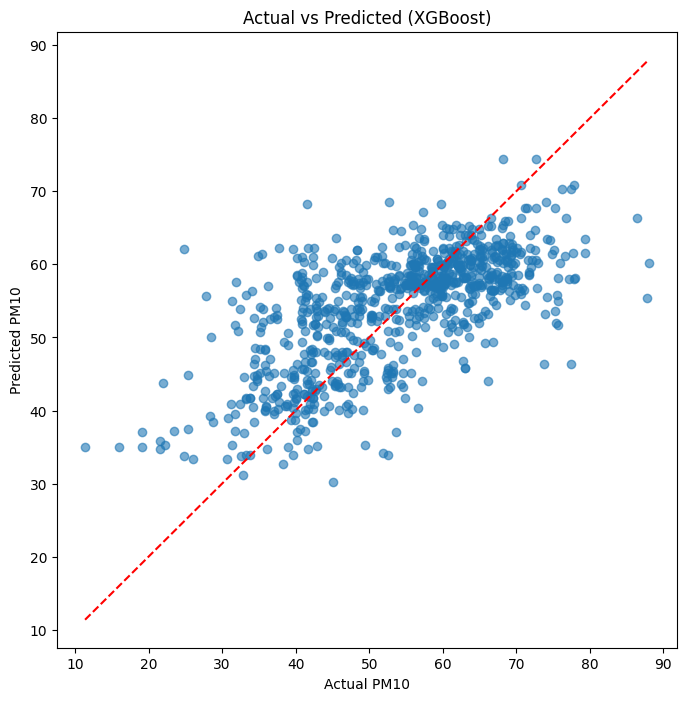

In [25]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    xgb_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual PM10")

plt.ylabel("Predicted PM10")

plt.title("Actual vs Predicted (XGBoost)")

plt.show()

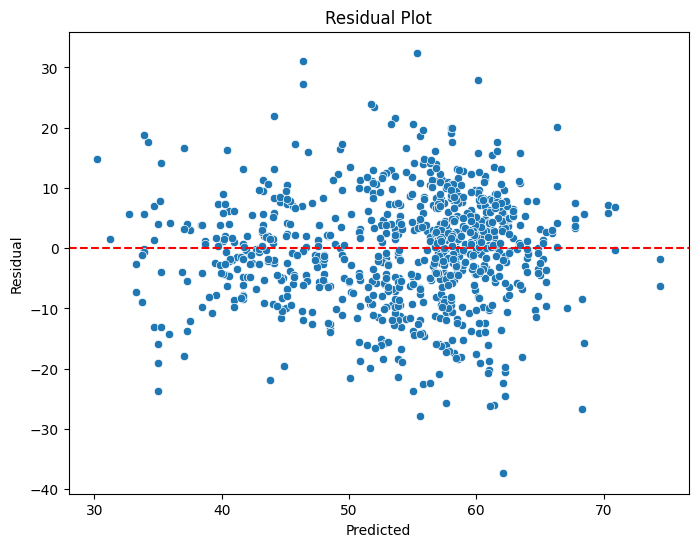

In [26]:
residuals = y_test - xgb_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=xgb_pred,
    y=residuals
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.show()

In [27]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

,Feature,Importance
2,RF-CUMULATIVE,0.421548
3,Wind_speed,0.250837
0,Temperature,0.169259
1,Relative_humidity,0.158356


C:\Users\DELL\AppData\Local\Temp\ipykernel_17508\3158664850.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


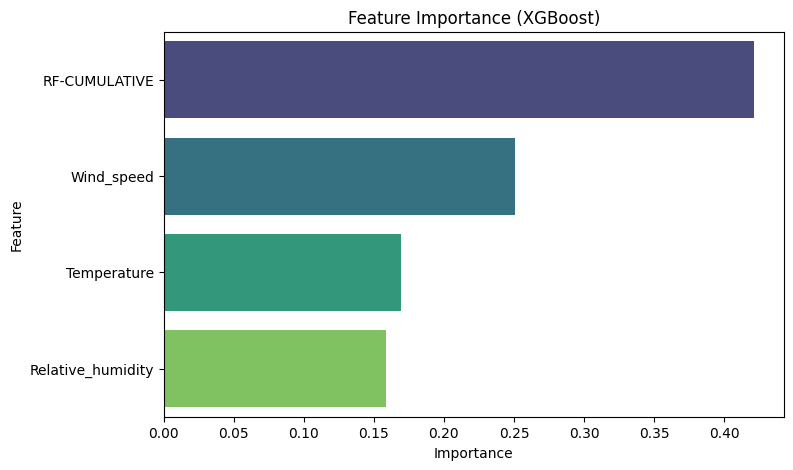

In [28]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Feature Importance (XGBoost)")

plt.show()

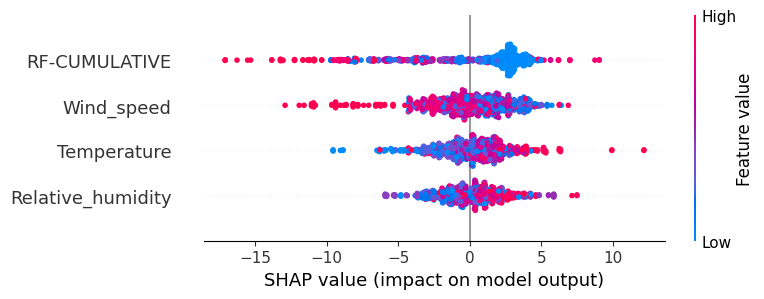

In [31]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)